# Madar Oman — flood mapping through cloud, with a stated noise floor

**Team T0045 · Theme 01 — Climate Adaptation and Disaster Recovery · Sultanate of Oman**

This notebook reproduces the headline result of the proof of concept: the new surface water that
Sentinel-1 radar saw at **Al Khaburah** (North Al Batinah) after **Cyclone Shaheen** made landfall on
3 October 2021, and — beside it — how much "new water" the *same method* reports on an ordinary day
with no event.

It reads only the files in `data/sample_input/`, needs no credentials and no network, and runs in
well under a minute on a laptop.

**The method in four rules**

1. *Flood is water now that is not water normally.* "Normally" is the median of five earlier passes
   of the **same viewing geometry**, so sea, dams and permanently dark sand drop out.
2. *Slopes over 5° and mapped permanent water are excluded* (radar shadow and the sea read as water).
3. *Patches under 0.5 ha are speckle* and are removed.
4. *The null test.* After the event, cells that already read as flood on any pre-event pass are
   removed. The same subtraction is then run on the last pre-event pass: what it leaves is what the
   method finds on an ordinary day. A flood is declared only if the event pass finds more.

In [1]:
# Only when opened in Google Colab: fetch the repository (sample data) and the one package Colab lacks.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("madar-oman-poc"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/qaisalbadaai/madar-oman-poc.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)
    os.chdir("madar-oman-poc")

In [2]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from scipy import ndimage

# Relative paths: the notebook runs from notebooks/ or from the repository root.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "sample_input"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

WATER_DB = -16.0      # VV backscatter below this reads as open water
MIN_PATCH_HA = 0.5    # smaller patches are speckle
manifest = json.loads((DATA / "manifest.json").read_text())
EVENT = manifest["event_date"]
RES = manifest["resolution_m"]
CELL_KM2 = RES ** 2 / 1e6
print(manifest["source"]); print("grid:", manifest["crs"], f"{RES} m", "| event:", EVENT)

Sentinel-1 RTC, Microsoft Planetary Computer (collection sentinel-1-rtc)
grid: EPSG:32640 20.0 m | event: 2021-10-03


## 1. Read the sample input

Ten Sentinel-1 passes of one viewing geometry (descending, relative orbit 93), clipped to the study area: five before the analysis period for the baseline, three in September before the cyclone, two after it.

In [3]:
def read(name):
    with rasterio.open(DATA / name) as src:
        return src.read(1), src.nodata, src.bounds

def read_db(name):
    raw, nodata, _ = read(name)
    return np.where(raw == nodata, np.nan, raw / 100.0)

passes = [dict(p, db=read_db(p["file"])) for p in manifest["passes"]]
excluded = read("excluded_slope_or_permanent_water.tif")[0].astype(bool)
inside = read("inside_area.tif")[0].astype(bool)
bounds = read("inside_area.tif")[2]
for p in passes:
    print(p["date"], p["role"], f"median {np.nanmedian(p['db']):6.2f} dB")
print("grid", inside.shape, "| study area", round(inside.sum() * CELL_KM2, 1), "km²")

2021-07-07 baseline median -11.42 dB
2021-07-19 baseline median -11.57 dB
2021-07-31 baseline median -11.52 dB
2021-08-12 baseline median -11.59 dB
2021-08-24 baseline median -11.62 dB
2021-09-05 analysis median -11.42 dB
2021-09-17 analysis median -11.41 dB
2021-09-29 analysis median -11.55 dB
2021-10-11 analysis median -10.92 dB
2021-10-23 analysis median -11.25 dB
grid (1110, 919) | study area 405.7 km²


## 2. The baseline: what this ground normally looks like

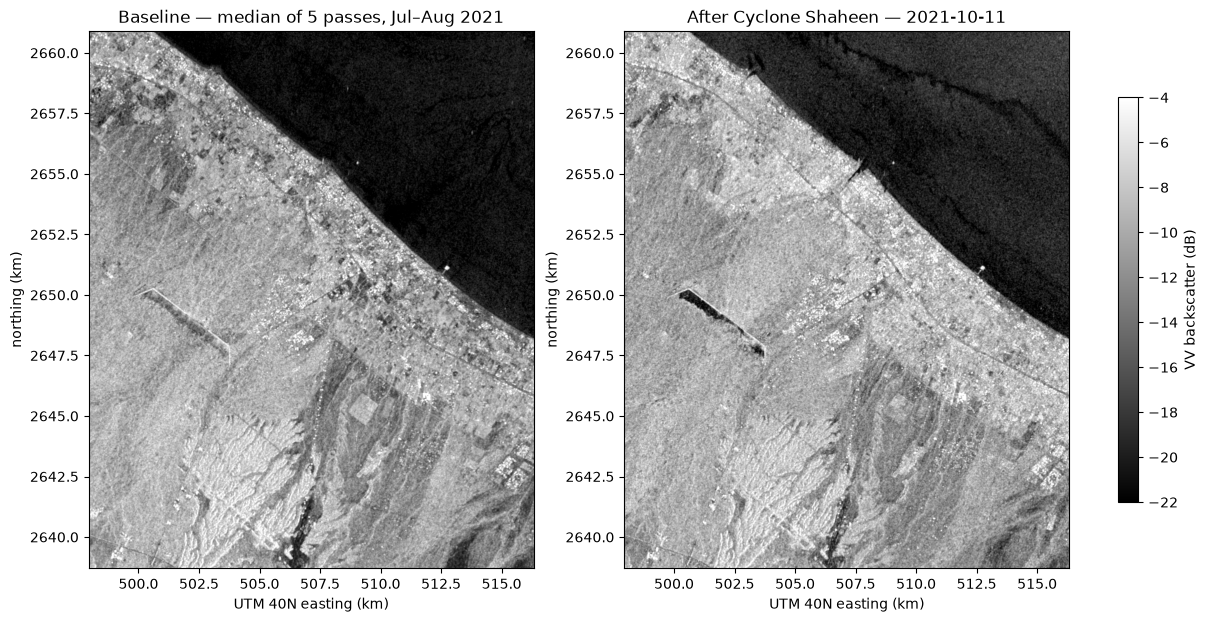

In [4]:
baseline = np.nanmedian(np.stack([p["db"] for p in passes if p["role"] == "baseline"]), axis=0)
event_pass = next(p for p in passes if p["date"] > EVENT)

extent = [bounds.left / 1000, bounds.right / 1000, bounds.bottom / 1000, bounds.top / 1000]
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), constrained_layout=True)
for ax, img, title in ((axes[0], baseline, "Baseline — median of 5 passes, Jul–Aug 2021"),
                       (axes[1], event_pass["db"], f"After Cyclone Shaheen — {event_pass['date']}")):
    im = ax.imshow(img, cmap="gray", vmin=-22, vmax=-4, extent=extent)
    ax.set_title(title); ax.set_xlabel("UTM 40N easting (km)"); ax.set_ylabel("northing (km)")
fig.colorbar(im, ax=axes, shrink=0.7, label="VV backscatter (dB)")
plt.show()

## 3. Flood mask for every pass

In [5]:
MIN_CELLS = max(1, round(MIN_PATCH_HA * 10_000 / RES ** 2))

def flood_mask(db):
    usable = inside & np.isfinite(db) & np.isfinite(baseline)
    wet_now = usable & (db < WATER_DB)
    wet_normally = usable & (baseline < WATER_DB)
    flood = wet_now & ~wet_normally & ~excluded
    labels, count = ndimage.label(flood, structure=np.ones((3, 3), dtype=bool))
    if not count:
        return flood
    sizes = ndimage.sum_labels(np.ones_like(labels), labels, index=np.arange(1, count + 1))
    return np.isin(labels, np.flatnonzero(sizes >= MIN_CELLS) + 1)

frames = [dict(p, mask=flood_mask(p["db"]), phase="before" if p["date"] < EVENT else "after")
          for p in passes if p["role"] == "analysis"]
for f in frames:
    print(f["date"], f["phase"], f"flood mask {f['mask'].sum() * CELL_KM2:.4f} km²")

2021-09-05 before flood mask 0.1560 km²
2021-09-17 before flood mask 0.1712 km²
2021-09-29 before flood mask 0.4616 km²
2021-10-11 after flood mask 0.8840 km²
2021-10-23 after flood mask 0.6484 km²


## 4. The null test

Speckle and soil moisture put "new water" on different cells in every pass. So the pre-event passes tell us what the method reports when nothing happened.

In [6]:
before = [f for f in frames if f["phase"] == "before"]
after = [f for f in frames if f["phase"] == "after"]

noise = np.logical_or.reduce([f["mask"] for f in before])            # ever flagged before the event
earlier = np.logical_or.reduce([f["mask"] for f in before[:-1]])
null_km2 = (before[-1]["mask"] & ~earlier).sum() * CELL_KM2          # an ordinary day, same subtraction

rows = []
for f in after:
    f["signal"] = f["mask"] & ~noise
    f["signal_km2"] = f["signal"].sum() * CELL_KM2
    rows.append((f["date"], f["mask"].sum() * CELL_KM2, f["signal_km2"], null_km2, f["signal_km2"] > null_km2))

print(f"{'pass':<12}{'flood mask km²':>16}{'new water km²':>16}{'ordinary day km²':>18}  above noise")
for date, mask_km2, signal, null, above in rows:
    print(f"{date:<12}{mask_km2:>16.4f}{signal:>16.4f}{null:>18.4f}  {above}")
peak = max(after, key=lambda f: f["signal_km2"])
print(f"\nHeadline: {peak['signal_km2']:.2f} km² of new water on {peak['date']}, "
      f"against {null_km2:.2f} km² on an ordinary day.")

pass          flood mask km²   new water km²  ordinary day km²  above noise
2021-10-11            0.8840          0.8776            0.4052  True
2021-10-23            0.6484          0.6360            0.4052  True

Headline: 0.88 km² of new water on 2021-10-11, against 0.41 km² on an ordinary day.


## 5. The map and the figures that go in the report

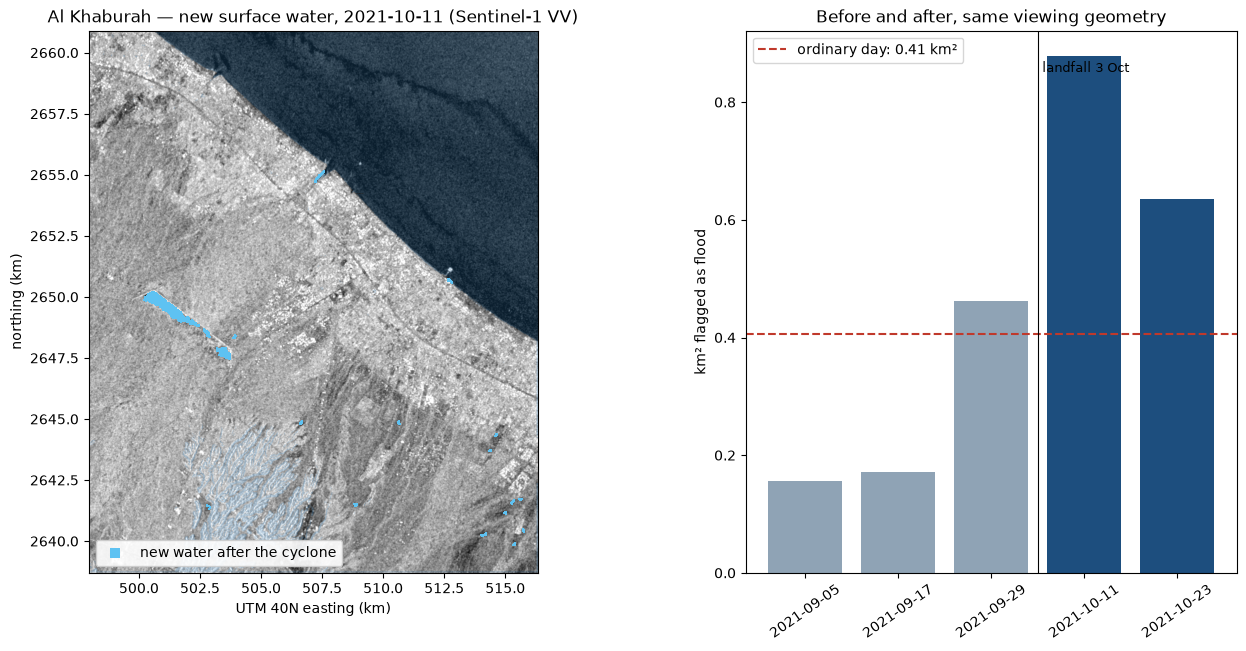

{'area': 'Al Khaburah — town and coastal plain',
 'event_date': '2021-10-03',
 'sensor': 'Sentinel-1 RTC VV',
 'geometry': 'descending_93',
 'resolution_m': 20.0,
 'water_threshold_db': -16.0,
 'peak_pass': '2021-10-11',
 'new_water_km2': 0.8776,
 'ordinary_day_km2': 0.4052,
 'above_noise': True,
 'passes': [{'date': '2021-10-11',
   'flood_mask_km2': 0.884,
   'new_water_km2': 0.8776},
  {'date': '2021-10-23', 'flood_mask_km2': 0.6484, 'new_water_km2': 0.636}]}

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.imshow(peak["db"], cmap="gray", vmin=-22, vmax=-4, extent=extent)
ax.imshow(np.ma.masked_where(~excluded, excluded), cmap="Blues", alpha=0.25, extent=extent, vmin=0, vmax=1.4)
ys, xs = np.nonzero(peak["signal"])
ax.scatter(extent[0] + (xs + 0.5) * RES / 1000, extent[3] - (ys + 0.5) * RES / 1000,
           s=3, c="#5EC2F2", marker="s", linewidths=0, label="new water after the cyclone")
ax.set_title(f"Al Khaburah — new surface water, {peak['date']} (Sentinel-1 VV)")
ax.set_xlabel("UTM 40N easting (km)"); ax.set_ylabel("northing (km)")
ax.legend(loc="lower left", markerscale=4, framealpha=0.9)

ax = axes[1]
labels = [f["date"] for f in before] + [f["date"] for f in after]
values = [f["mask"].sum() * CELL_KM2 for f in before] + [f["signal_km2"] for f in after]
colors = ["#8FA3B5"] * len(before) + ["#1D4E7E"] * len(after)
ax.bar(labels, values, color=colors)
ax.axhline(null_km2, color="#C0392B", ls="--", lw=1.5, label=f"ordinary day: {null_km2:.2f} km²")
ax.axvline(len(before) - 0.5, color="k", lw=0.8); ax.text(len(before) - 0.45, max(values) * 0.97, "landfall 3 Oct", fontsize=9)
ax.set_ylabel("km² flagged as flood"); ax.set_title("Before and after, same viewing geometry")
ax.tick_params(axis="x", rotation=35); ax.legend(loc="upper left")
fig.savefig(RESULTS / "khaburah_flood_shaheen_2021.png", dpi=140)
plt.show()

summary = {"area": "Al Khaburah — town and coastal plain", "event_date": EVENT, "sensor": "Sentinel-1 RTC VV",
           "geometry": manifest["geometry"], "resolution_m": RES, "water_threshold_db": WATER_DB,
           "peak_pass": peak["date"], "new_water_km2": round(float(peak["signal_km2"]), 4),
           "ordinary_day_km2": round(float(null_km2), 4), "above_noise": bool(peak["signal_km2"] > null_km2),
           "passes": [{"date": d, "flood_mask_km2": round(float(m), 4), "new_water_km2": round(float(s), 4)}
                      for d, m, s, _, _ in rows]}
(RESULTS / "khaburah_flood_summary.json").write_text(json.dumps(summary, indent=2))
with rasterio.open(DATA / "inside_area.tif") as src:
    profile = src.profile
profile.update(dtype="uint8", nodata=0, compress="deflate")
with rasterio.open(RESULTS / "khaburah_new_water_mask.tif", "w", **profile) as dst:
    dst.write(peak["signal"].astype("uint8"), 1)
summary

## 6. Reading the result

- **0.88 km² of new water** on 11 October 2021, against **0.41 km²** that the same method reports on an
  ordinary day: a flood is detected, at roughly twice the noise floor. The full platform finds the same
  in the second viewing geometry (ascending 57), which is not included in this sample.
- About half of the new water is the Wadi Al Hawasnah dam reservoir filling — real water, not damage.
- **What this does not show.** The first usable pass is eight days after landfall, so the peak was
  missed. Radar cannot see water inside dense built-up areas. Thresholding at −16 dB misses
  wind-roughened and vegetated water. There is no ground survey of this event; agreement between two
  viewing geometries is consistency, not validation.
- **When the method says no.** Run on Al Musannah, where the cyclone made landfall, the platform
  measures 2.17 km² against a 2.03 km² noise floor — not distinguishable, and reported that way.